# Differential-loop APA by cell type — final 10-type annotation

Rebuilds `all_diffloop_apa_powernorm_sharedcbar.pdf` at **25 kb** under the final
annotation (`subset_clustering/250kb_denovo`, k20_r0.3), using **all 1,577 cells**.

Rows = the Hi-C of one cell type. Columns = the loops assigned specifically to
one cell type. A cell type's own loops should light up its own Hi-C, so the
diagonal should be the brightest panel in both its row and its column.

## Kernel

Run this with the **`hic_env`** conda environment (schicluster 1.3.5.dev, cooler):

```bash
conda activate hic_env
jupyter lab
```

## Prerequisites — already done, do NOT re-run unless the annotation changes

Everything this notebook reads was produced by two SLURM jobs in
`hic/loop_final/` (see `JOBS.md` for the full record):

| step | script | job | note |
|------|--------|-----|------|
| per-cell impute + loop-bkg, 25 kb | `impute_missing_25kb.sh` | `9921049` | filled the 434 cells Quest was missing, so Q **and** T exist for all 1,577. **Annotation-independent** — never needs redoing for a label change. |
| per-cell-type loops + Q/T/E cools | `call_loops_1577.sh` | `9930643` | ~13–47 min per cell type |

If the cell-type labels ever change, only the second step repeats: rebuild
`cell_table_all1577_25kb.tsv` from the annotation and resubmit
`call_loops_1577.sh`.

## Two fixes relative to the original `hic/save.py`

1. **All 19 autosomes.** `save.py` iterates `chrom_sizes.index[:-1]`; because the
   chrom file is lexically sorted (`chr1, chr10..chr19, chr2..chr9`) that drops
   **chr9**, a real autosome — not a trailing `chrM`/`chrY`. The old figure used 18.
2. **Correct axis labels.** `save.py` labels the panels ±100k, but with
   `res = 25000` and a ±10-bin window they span **±250 kb**.


## 1 — Configuration

In [1]:
import os
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import cooler

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

mpl.rcParams["pdf.fonttype"] = 42          # editable text in Illustrator
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]

HIC    = "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/hic"
INDIR  = f"{HIC}/loop_majortype_25kb_1577"      # per-cell-type loops + Q/T cools
OUTDIR = f"{HIC}/loop_final/apa_1577"           # figures + cached intermediates
CHROM_FILE = "/gpfs/projects/b1198/epifluidlab/yoshii/reference/mm10/mm10.noX.autosome.sizes"
os.makedirs(OUTDIR, exist_ok=True)

RES   = 25000      # loop resolution
DIST  = 505        # max diagonal offset used for the distance-decay expectation
HALF  = 10         # window is 2*HALF+1 = 21 bins  ->  +/- 250 kb at 25 kb
CPU   = 5
FC_THRESH = 1.2    # a loop is "specific" if fc(Q) AND fc(T) exceed this

# excitatory first, then inhibitory, then glia/vascular -- neurons stay adjacent,
# matching the order used throughout the annotation notebook
LEG     = ["IT-L2_3", "IT-L4", "IT-L5_6", "CT-L6", "Inhib",
           "ODC", "OPC", "ASC", "MGC", "PC_EC"]
LEGNAME = ["IT-L2/3", "IT-L4", "IT-L5/6", "CT-L6", "Inhib",
           "ODC", "OPC", "ASC", "MGC", "PC/EC"]

chrom_sizes = cooler.read_chromsizes(CHROM_FILE, all_names=True)
# NOTE: sort numerically and keep ALL 19 -- see the header cell on the chr9 bug
CHROMS = sorted(chrom_sizes.index, key=lambda c: int(str(c).replace("chr", "")))
print(f"{len(CHROMS)} chromosomes:", CHROMS)

19 chromosomes: ['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19']


## 2 — Union of the per-cell-type loop calls

Each cell type contributes its own loop calls; we take the union and deduplicate
on `(chrom, start1, start2)` so every loop is scored once against every type.

In [2]:
parts = []
for ct in LEG:
    df = pd.read_csv(f"{INDIR}/{ct}/{ct}/{ct}.loop.bedpe", sep="\t", header=None)
    print(f"  {ct:9s} {df.shape[0]:6d} loops")
    parts.append(df)

loopall = pd.concat(parts, axis=0, ignore_index=True)
if loopall.shape[1] > 6:
    loopall = loopall[[0, 1, 2, 3, 4, 5]]
loopall = loopall.drop_duplicates(subset=[0, 1, 4]).sort_values([0, 1, 4])
loopall = pd.concat([loopall[loopall[0] == c] for c in CHROMS], axis=0, ignore_index=True)

print(f"\nunion: {loopall.shape[0]} distinct loops")
loopall.to_csv(f"{OUTDIR}/merged_loop.bedpe", sep="\t", index=False, header=False)
loopall.head()

  IT-L2_3    21922 loops
  IT-L4      21042 loops
  IT-L5_6    20702 loops


  CT-L6      18812 loops


  Inhib      21727 loops
  ODC        19140 loops
  OPC        17269 loops
  ASC        20342 loops


  MGC        19783 loops


  PC_EC      16935 loops

union: 49196 distinct loops


,0,1,2,3,4,5
0,chr1,5275000,5300000,chr1,5350000,5375000
1,chr1,8575000,8600000,chr1,9500000,9525000
2,chr1,9575000,9600000,chr1,9650000,9675000
3,chr1,9575000,9600000,chr1,9675000,9700000
4,chr1,9600000,9625000,chr1,9675000,9700000


## 3 — Q and T at every loop anchor

`Q` is the imputed contact matrix, `T` the local-background-normalised one. Both
must come from the **same cells**, or the two fold-changes below are not
comparable — that is why the pipeline builds them together from one cell table.

Cached: re-running the notebook reloads the HDFs instead of re-reading the coolers.

In [3]:
def _load_vals(args):
    """Value at each loop anchor pair, for one cell type and one matrix type."""
    ct, m = args
    mat = cooler.Cooler(f"{INDIR}/{ct}/{ct}/{ct}.{m}.cool").matrix(balance=False, sparse=True)
    out = []
    for c in CHROMS:
        sub = loopall.loc[loopall[0] == c]
        if sub.empty:
            continue
        csr = mat.fetch(c).tocsr()
        out.append(csr[(sub[1].values // RES, sub[4].values // RES)].A1)
    return ct, m, np.concatenate(out)


def load_matrix(m):
    cache = f"{OUTDIR}/loop_{m}.hdf"
    if os.path.exists(cache):
        print(f"[cached] {cache}")
        return pd.read_hdf(cache, key="data")
    res = {}
    with ProcessPoolExecutor(CPU) as ex:
        futs = [ex.submit(_load_vals, (ct, m)) for ct in LEG]
        for f in as_completed(futs):
            ct, mm, v = f.result()
            res[ct] = v
            print(f"  {mm}: {ct} done")
    out = pd.DataFrame({ct: res[ct] for ct in LEG})
    out.to_hdf(cache, key="data")
    return out


loopq = load_matrix("Q")
loopt = load_matrix("T")
print(loopq.shape, loopt.shape)

[cached] /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/hic/loop_final/apa_1577/loop_Q.hdf


[cached] /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/hic/loop_final/apa_1577/loop_T.hdf
(49196, 10) (49196, 10)


## 4 — Assign each loop to a cell type

A loop belongs to a cell type when **both** its Q and its T exceed 1.2× the mean
of the other nine types. Loops failing that in every type are `unassigned` and
are dropped from the figure.

In [4]:
eps = 1e-9
fc1 = pd.DataFrame(index=loopq.index, columns=LEG, dtype=float)
fc2 = pd.DataFrame(index=loopt.index, columns=LEG, dtype=float)
for ct in LEG:
    fc1[ct] = (loopq[ct].astype(float) + eps) / (loopq.loc[:, loopq.columns != ct].mean(axis=1) + eps)
    fc2[ct] = (loopt[ct].astype(float) + eps) / (loopt.loc[:, loopt.columns != ct].mean(axis=1) + eps)

member = (fc1 > FC_THRESH) & (fc2 > FC_THRESH)
score  = np.log2(fc1.clip(lower=eps)) + np.log2(fc2.clip(lower=eps))   # == log2(fc1*fc2), safely

s = score.to_numpy(dtype=float)
s[~np.isfinite(s)] = -np.inf                       # never let a NaN win the argmax
best_j = s.argmax(axis=1)
best   = s[np.arange(s.shape[0]), best_j]

ct_arr = np.array(LEG, dtype=object)[best_j]
ct_arr[~np.isfinite(best)] = "unassigned"
passes = member.to_numpy(dtype=bool)[np.arange(s.shape[0]), best_j]
keep = ct_arr != "unassigned"
ct_arr[keep] = np.where(passes[keep], ct_arr[keep], "unassigned")

assigned = loopall.copy()
assigned["assigned_ct"]  = ct_arr
assigned["assign_score"] = best
assigned.to_csv(f"{OUTDIR}/loop_assignments.tsv", sep="\t", index=False)

conf = assigned[assigned["assigned_ct"] != "unassigned"]
print(assigned["assigned_ct"].value_counts().to_string())
print(f"\nassigned {len(conf)} / {len(assigned)} loops")

assigned_ct
unassigned    15046
Inhib          5320
PC_EC          5309
OPC            5157
IT-L2_3        3750
IT-L4          3451
MGC            3304
IT-L5_6        2386
CT-L6          2104
ASC            1846
ODC            1523

assigned 34150 / 49196 loops


## 5 — APA pileup

For each cell type's Hi-C, take the observed/expected matrix (observed divided by
its own distance-decay), cut a 21×21 window around every loop of every group,
min-max normalise each window, and average. Cached to `apa_25kb.npz`.

In [5]:
loop_groups = [conf.loc[conf["assigned_ct"] == ct, [0, 1, 2, 3, 4, 5]].copy() for ct in LEG]


def apa_one(ct):
    result = np.zeros((len(loop_groups), 2 * HALF + 1, 2 * HALF + 1), dtype=float)
    counts = np.zeros(len(loop_groups), dtype=float)
    cool = cooler.Cooler(f"{INDIR}/{ct}/{ct}/{ct}.Q.cool")

    for c in CHROMS:
        Q = cool.matrix(balance=False, sparse=True).fetch(c).toarray()
        n = Q.shape[0]
        d = min(DIST, n)
        decay = np.array([np.nanmean(np.diag(Q, k)) for k in range(d)], dtype=float)
        decay[decay == 0] = np.nan                       # avoid divide-by-zero

        E = np.zeros_like(Q, dtype=float)
        row, col = np.diag_indices(n)
        E[row, col] = 1.0
        for k in range(1, d):
            vals = Q[row[:-k], col[k:]] / decay[k]
            E[row[:-k], col[k:]] = np.nan_to_num(vals, nan=0.0, posinf=0.0, neginf=0.0)

        for j, loop in enumerate(loop_groups):
            sub = loop.loc[loop[0] == c, [1, 4]]
            if sub.empty:
                continue
            for xx, yy in (sub.values // RES).astype(int):
                if xx - HALF < 0 or yy - HALF < 0 or xx + HALF + 1 > n or yy + HALF + 1 > n:
                    continue                              # window would run off the chromosome
                tmp = E[(xx - HALF):(xx + HALF + 1), (yy - HALF):(yy + HALF + 1)]
                mn, mx = np.nanmin(tmp), np.nanmax(tmp)
                if not np.isfinite(mn) or not np.isfinite(mx) or mx <= mn:
                    continue
                result[j] += (tmp - mn) / (mx - mn)
                counts[j] += 1

    for j in range(len(loop_groups)):
        result[j] /= max(1.0, counts[j])
    return ct, result, counts


cache = f"{OUTDIR}/apa_25kb.npz"
if os.path.exists(cache):
    print(f"[cached] {cache}")
    z = np.load(cache, allow_pickle=True)
    result, counts = z["result"], z["counts"]
else:
    result = np.zeros((len(LEG), len(LEG), 2 * HALF + 1, 2 * HALF + 1))
    counts = np.zeros((len(LEG), len(LEG)))
    with ProcessPoolExecutor(CPU) as ex:
        futs = {ex.submit(apa_one, ct): ct for ct in LEG}
        for f in as_completed(futs):
            ct, r, c = f.result()
            i = LEG.index(ct)
            result[i], counts[i] = r, c
            print(f"  APA {ct} done")
    np.savez_compressed(cache, result=result, counts=counts,
                        leg=np.array(LEG), groups=np.array(LEG))
print(result.shape)

[cached] /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/hic/loop_final/apa_1577/apa_25kb.npz
(10, 10, 21, 21)


## 6 — The figure

`GAMMA` is the only knob worth touching: `PowerNorm` compresses the top of the
range so the centre dot stays legible without the background washing out. Lower
gamma = more contrast in the dim values. Limits are shared across all 100 panels
so the colours are directly comparable; the number above each panel is the APA
score (centre pixel ÷ mean of the lower-left corner).

wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/hic/loop_final/apa_1577/all_diffloop_apa_powernorm_sharedcbar.pdf


wrote /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/hic/loop_final/apa_1577/all_diffloop_apa_powernorm_sharedcbar.png


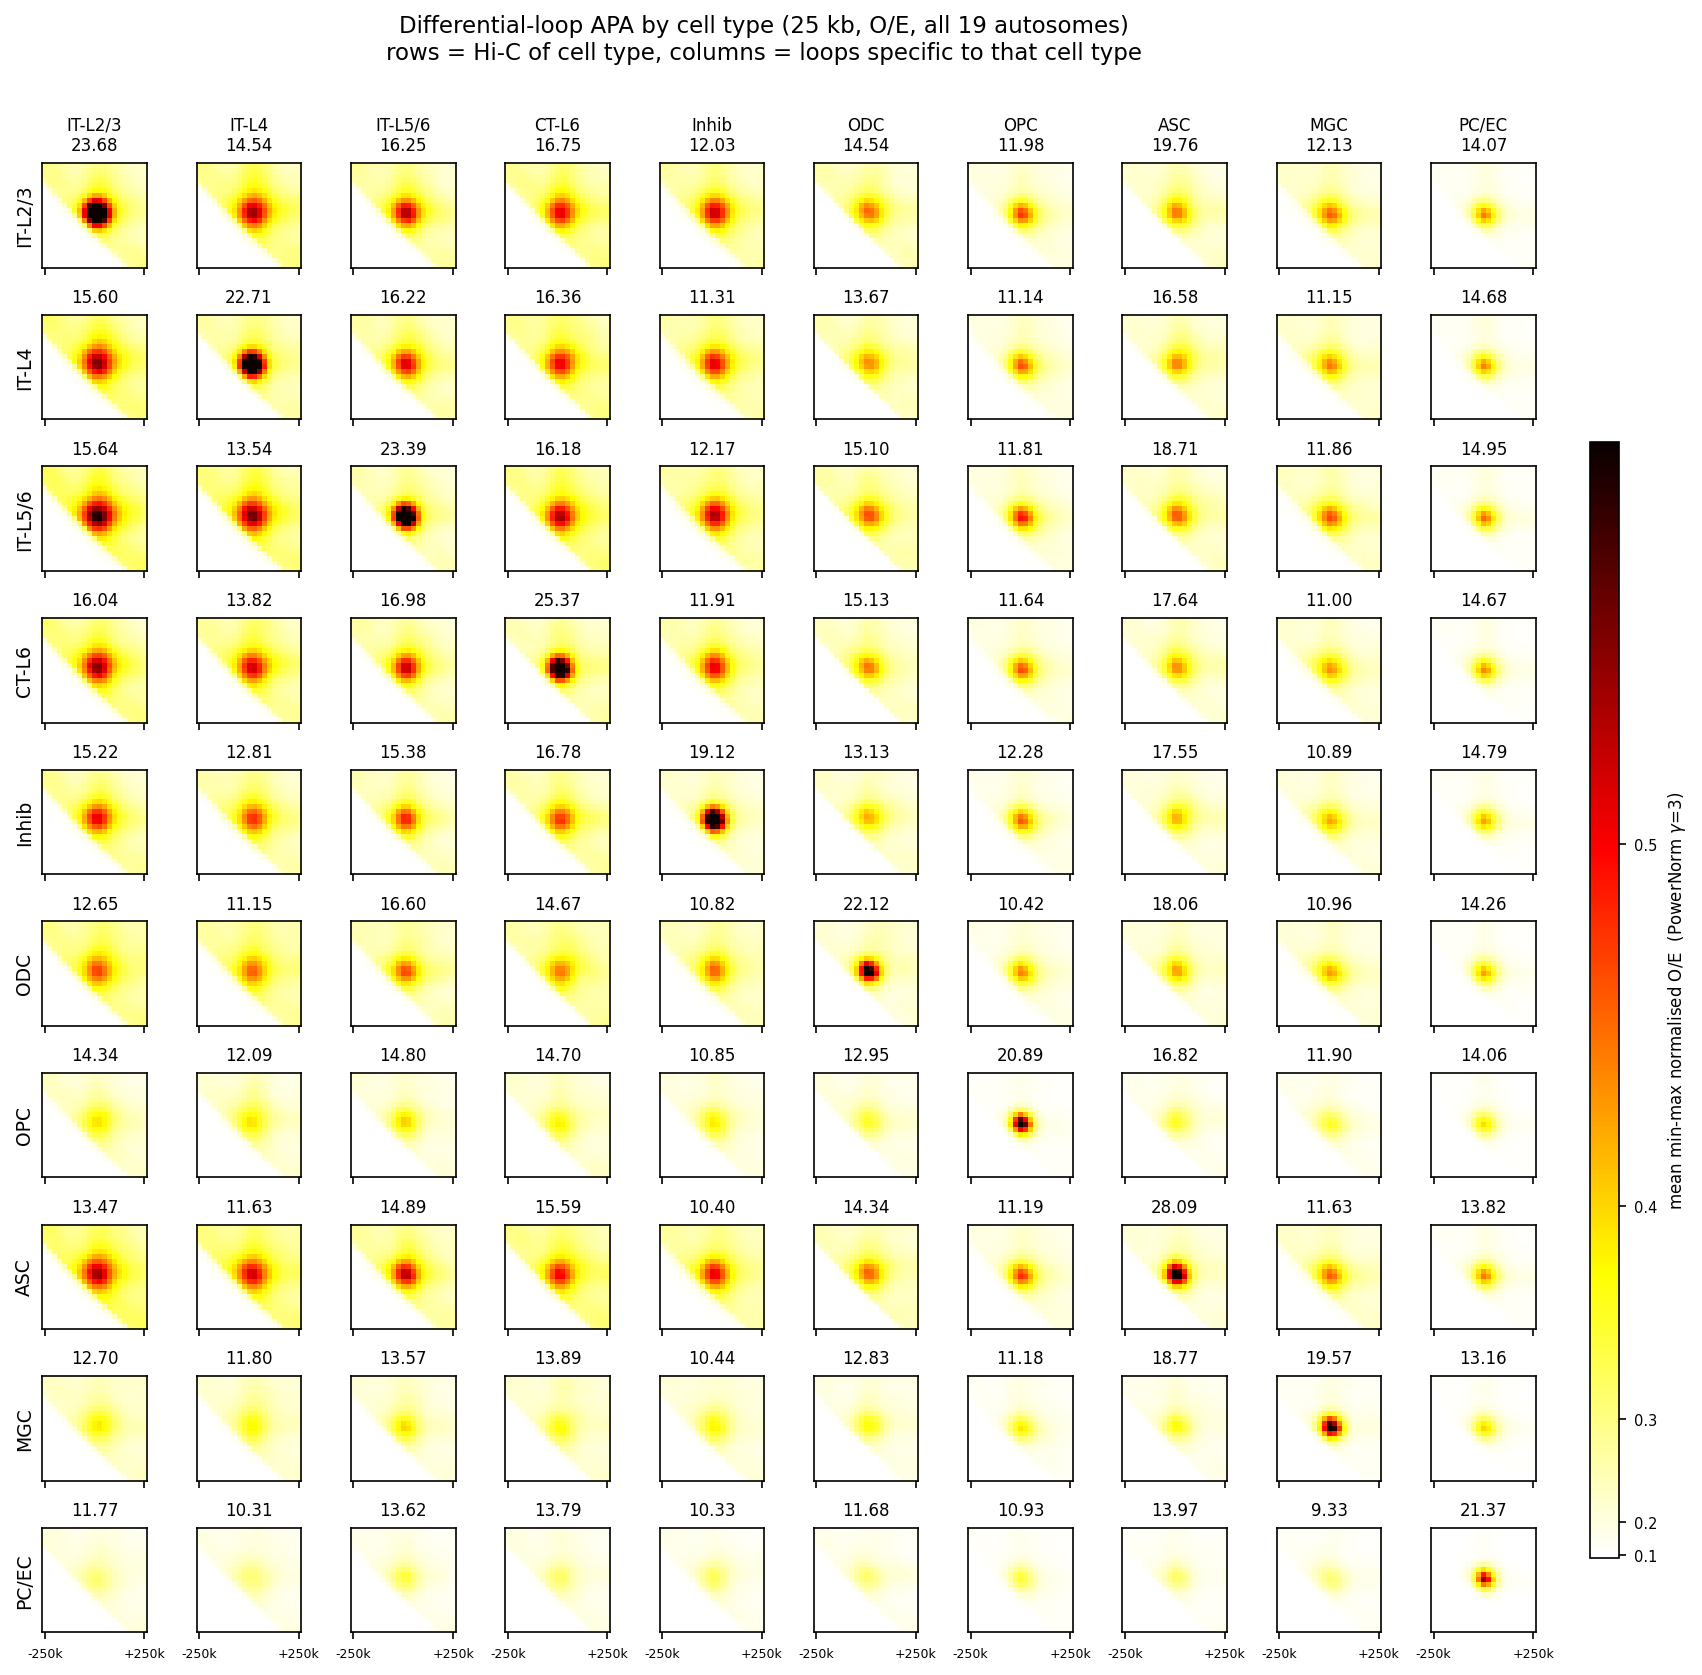

In [6]:
GAMMA = 3

n = len(LEG)
vmin = float(np.nanpercentile(result, 1))
vmax = float(np.nanpercentile(result, 99.9))
norm = PowerNorm(gamma=GAMMA, vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(n, n, figsize=(n * 1.15 + 1.6, n * 1.15 + 0.9),
                         sharex="all", sharey="all", dpi=150)
scores = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        tmp = result[i, j]
        corner = tmp[-5:, :5].mean()
        scores[i, j] = tmp[HALF, HALF] / corner if corner > 0 else np.nan
        im = ax.imshow(tmp, cmap="hot_r", norm=norm)
        ax.set_title(f"{LEGNAME[j]}\n{scores[i, j]:.2f}" if i == 0 else f"{scores[i, j]:.2f}",
                     fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(LEGNAME[i], fontsize=9)
for j in range(n):
    axes[-1, j].set_xticks([0, 2 * HALF])
    axes[-1, j].set_xticklabels(["-250k", "+250k"], fontsize=6)   # 10 bins x 25 kb

fig.suptitle("Differential-loop APA by cell type (25 kb, O/E, all 19 autosomes)\n"
             "rows = Hi-C of cell type, columns = loops specific to that cell type",
             fontsize=11)
fig.subplots_adjust(right=0.90, top=0.90, wspace=0.15, hspace=0.45)
cax = fig.add_axes([0.92, 0.15, 0.015, 0.6])
cb = fig.colorbar(im, cax=cax)
cb.set_label(f"mean min-max normalised O/E  (PowerNorm $\\gamma$={GAMMA})", fontsize=8)
cb.ax.tick_params(labelsize=7)

for ext in ("pdf", "png"):
    p = f"{OUTDIR}/all_diffloop_apa_powernorm_sharedcbar.{ext}"
    fig.savefig(p, transparent=(ext == "pdf"), bbox_inches="tight")
    print("wrote", p)
plt.show()

## 7 — Check the diagonal

The claim the figure supports is that each cell type's loops are strongest in
that cell type's own Hi-C. This checks it numerically rather than by eye: the
diagonal should be the maximum of both its row and its column.

In [7]:
tab = pd.DataFrame(scores, index=LEGNAME, columns=LEGNAME).round(2)
diag = pd.DataFrame({
    "own": np.diag(scores).round(2),
    "best_other_in_row": [max(scores[i, j] for j in range(n) if j != i) for i in range(n)],
    "best_other_in_col": [max(scores[i, j] for i in range(n) if i != j) for j in range(n)],
}, index=LEGNAME).round(2)
diag["row_max"] = diag["own"] > diag["best_other_in_row"]
diag["col_max"] = diag["own"] > diag["best_other_in_col"]
print(diag.to_string())
print(f"\ndiagonal is BOTH row and column max for "
      f"{int((diag.row_max & diag.col_max).sum())}/{n} cell types")
tab

           own  best_other_in_row  best_other_in_col  row_max  col_max
IT-L2/3  23.68              19.76              16.04     True     True
IT-L4    22.71              16.58              14.54     True     True
IT-L5/6  23.39              18.71              16.98     True     True
CT-L6    25.37              17.64              16.78     True     True
Inhib    19.12              17.55              12.17     True     True
ODC      22.12              18.06              15.13     True     True
OPC      20.89              16.82              12.28     True     True
ASC      28.09              15.59              19.76     True     True
MGC      19.57              18.77              12.13     True     True
PC/EC    21.37              13.97              14.95     True     True

diagonal is BOTH row and column max for 10/10 cell types


,IT-L2/3,IT-L4,IT-L5/6,CT-L6,Inhib,ODC,OPC,ASC,MGC,PC/EC
IT-L2/3,23.68,14.54,16.25,16.75,12.03,14.54,11.98,19.76,12.13,14.07
IT-L4,15.60,22.71,16.22,16.36,11.31,13.67,11.14,16.58,11.15,14.68
IT-L5/6,15.64,13.54,23.39,16.18,12.17,15.10,11.81,18.71,11.86,14.95
CT-L6,16.04,13.82,16.98,25.37,11.91,15.13,11.64,17.64,11.00,14.67
Inhib,15.22,12.81,15.38,16.78,19.12,13.13,12.28,17.55,10.89,14.79
ODC,12.65,11.15,16.60,14.67,10.82,22.12,10.42,18.06,10.96,14.26
OPC,14.34,12.09,14.80,14.70,10.85,12.95,20.89,16.82,11.90,14.06
ASC,13.47,11.63,14.89,15.59,10.40,14.34,11.19,28.09,11.63,13.82
MGC,12.70,11.80,13.57,13.89,10.44,12.83,11.18,18.77,19.57,13.16
PC/EC,11.77,10.31,13.62,13.79,10.33,11.68,10.93,13.97,9.33,21.37
